In [ ]:
import os
import numpy as np
from scipy import stats
import statsmodels.stats.multitest as smm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import and clean up

In [3]:
df = pd.read_csv("DDA_plus_RefSeq.tsv",sep="\t",index_col=0)
procols=["Pro_1 MaxLFQ Intensity","Pro_2 MaxLFQ Intensity",\
        "Pro_3 MaxLFQ Intensity","Pro_4 MaxLFQ Intensity",\
            "Pro_5 MaxLFQ Intensity"]
laccols=["Lac_1 MaxLFQ Intensity","Lac_2 MaxLFQ Intensity",\
        "Lac_3 MaxLFQ Intensity","Lac_4 MaxLFQ Intensity",\
            "Lac_5 MaxLFQ Intensity"]
pycols=["PY_1 MaxLFQ Intensity","PY_2 MaxLFQ Intensity",\
        "PY_3 MaxLFQ Intensity","PY_4 MaxLFQ Intensity",\
            "PY_5 MaxLFQ Intensity"]
pro=df[procols]
lac=df[laccols]
py=df[pycols]

In [4]:
volcano=pd.DataFrame(index=df.index)
volcano["Name"] = df["Description"]
volcano=pd.concat([volcano, py, pro, lac], axis=1)

volcano.replace(0, np.nan, inplace=True)
print("Before dropping NaN: " + str(len(volcano)))

log2vol = volcano.iloc[:, 1:].apply(np.log2)
log2vol = log2vol.subtract(log2vol.median(axis=0), axis=1)

min_reps = 2 # proteins need to be observed in 1/5 replicates
mask = (
    (log2vol[procols].notna().sum(axis=1) >= min_reps) &
    (log2vol[laccols].notna().sum(axis=1) >= min_reps) &
    (log2vol[pycols].notna().sum(axis=1) >= min_reps)
)
log2fvol = log2vol[mask]
print(f"Proteins retained after filtering: {len(log2fvol)}")

Before dropping NaN: 991
Proteins retained after filtering: 767


## Welch's T-test to BH FDR:

In [5]:
volcano.loc[mask, "l2fc_propy"]  = log2fvol[procols].mean(axis=1) - log2fvol[pycols].mean(axis=1)
volcano.loc[mask, "l2fc_lacpy"]  = log2fvol[laccols].mean(axis=1) - log2fvol[pycols].mean(axis=1)
volcano.loc[mask, "l2fc_prolac"] = log2fvol[procols].mean(axis=1) - log2fvol[laccols].mean(axis=1)

def welch_t(group1, group2):
    """Return p-value from Welch's t-test, ignoring NaN."""
    g1 = group1.dropna()
    g2 = group2.dropna()
    if len(g1) < 2 or len(g2) < 2:
        return np.nan
    return stats.ttest_ind(g1, g2, equal_var=False).pvalue

p_propy  = log2fvol.apply(lambda row: welch_t(row[procols], row[pycols]), axis=1)
p_lacpy  = log2fvol.apply(lambda row: welch_t(row[laccols], row[pycols]), axis=1)
p_prolac = log2fvol.apply(lambda row: welch_t(row[procols], row[laccols]), axis=1)

volcano.loc[mask, "pval_propy"]  = p_propy
volcano.loc[mask, "pval_lacpy"]  = p_lacpy
volcano.loc[mask, "pval_prolac"] = p_prolac

for comp in ["propy", "lacpy", "prolac"]:
    pvals = volcano.loc[mask, f"pval_{comp}"]
    reject, pvals_bh, _, _ = smm.multipletests(pvals, method='fdr_bh')
    volcano.loc[mask, f"adj_pval_{comp}"] = pvals_bh
    volcano.loc[mask, f"neglog10_adj_pval_{comp}"] = -np.log10(pvals_bh)

## Plot

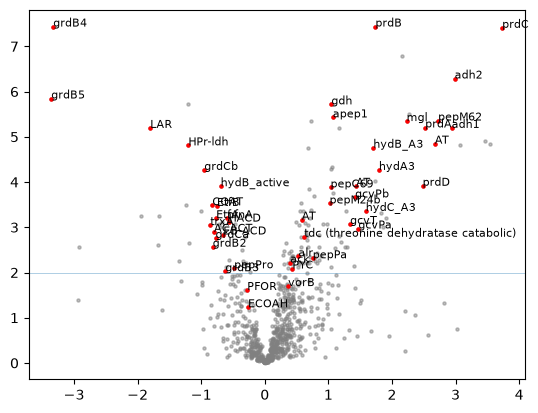

In [ ]:
annots = pd.read_excel("annotations.xlsx")
annots.columns = ["colour","shorthand", "ProteinID", "FullName"]

highlight = volcano.loc[volcano.index.isin(annots['ProteinID'])].copy()
highlight = highlight.merge(annots, left_index=True, right_on="ProteinID")

plotdata = volcano[["l2fc_prolac","neglog10_adj_pval_prolac"]]
calloutdata = highlight[(highlight["neglog10_adj_pval_prolac"] > 1.95) | (highlight["shorthand"].isin(["PFOR","OFOR", "ECOAH", "vorB"]))] 

plt.scatter(plotdata["l2fc_prolac"], plotdata["neglog10_adj_pval_prolac"], s=5, c="grey", alpha=0.5)
plt.axhline(2, lw=0.5, alpha=0.5)
plt.scatter(calloutdata["l2fc_prolac"], calloutdata["neglog10_adj_pval_prolac"],s=5, c="red")
for i, row in calloutdata.iterrows():
    plt.text(row['l2fc_prolac'], row['neglog10_adj_pval_prolac'], row['shorthand'], fontsize=8)  